# 01 · Exploratory data analysis: Texas weekly sales

**Question this project answers:** how much of each item will each Texas store sell over the next 4 weeks, how confident are we, and how much should we stock?

This notebook looks at the weekly table built by `python -m forecast.data` (`data/processed/tx_weekly.parquet`) before any modeling. It covers:

1. What the table contains
2. Volume by store and department
3. Listings over time ("not yet listed" weeks)
4. Zero-sales weeks (intermittent demand)
5. Seasonality
6. Store closures (Christmas week)
7. Series that recently went silent
8. What this means for modeling

> **Sales are not demand.** M5 has no inventory data. A week with zero sales may mean nobody wanted the item, or that it was out of stock. Every conclusion below is about *sales*.

All numbers in this notebook are computed by the code cells; none are typed by hand.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from forecast import PROCESSED_DIR
from forecast.plotting import STORE_COLORS, SINGLE_COLOR, MUTED, INK_SECONDARY, apply_style, thousands

apply_style()
df = pd.read_parquet(PROCESSED_DIR / "tx_weekly.parquet")
STORES = list(STORE_COLORS)

## 1. What the table contains

One row per item × store × Walmart week (Saturday to Friday), starting from the item's first listed week. Columns: units sold, the weekly sell price, and weekly calendar counts (SNAP days, event days, days open).

In [2]:
n_series = df.groupby(["item_id", "store_id"], observed=True).ngroups
print(f"Rows:            {len(df):,}")
print(f"Item-stores:     {n_series:,}  ({df['item_id'].nunique():,} items x {df['store_id'].nunique()} stores)")
print(f"Weeks:           {df['wm_yr_wk'].nunique()}  ({df['week_start'].min():%Y-%m-%d} to {df['week_start'].max():%Y-%m-%d}, week starts)")
print(f"Departments:     {', '.join(df['dept_id'].cat.categories)}")
print(f"Total units:     {df['sales'].sum():,}")
df.head()

Rows:            2,046,387
Item-stores:     9,147  (3,049 items x 3 stores)
Weeks:           277  (2011-01-29 to 2016-05-14, week starts)
Departments:     FOODS_1, FOODS_2, FOODS_3, HOBBIES_1, HOBBIES_2, HOUSEHOLD_1, HOUSEHOLD_2
Total units:     19,199,909


,item_id,dept_id,cat_id,store_id,wm_yr_wk,sales,sell_price,week_start,n_snap_days,n_event_days,days_open,is_christmas_week
0,FOODS_1_001,FOODS_1,FOODS,TX_1,11101,2,2.0,2011-01-29,2,0,7,False
1,FOODS_1_001,FOODS_1,FOODS,TX_1,11102,4,2.0,2011-02-05,5,1,7,False
2,FOODS_1_001,FOODS_1,FOODS,TX_1,11103,0,2.0,2011-02-12,3,1,7,False
3,FOODS_1_001,FOODS_1,FOODS,TX_1,11104,5,2.0,2011-02-19,0,1,7,False
4,FOODS_1_001,FOODS_1,FOODS,TX_1,11105,4,2.0,2011-02-26,2,0,7,False


## 2. Volume by store and department

Weekly total units per store. The dotted vertical lines mark the Christmas weeks (section 6).

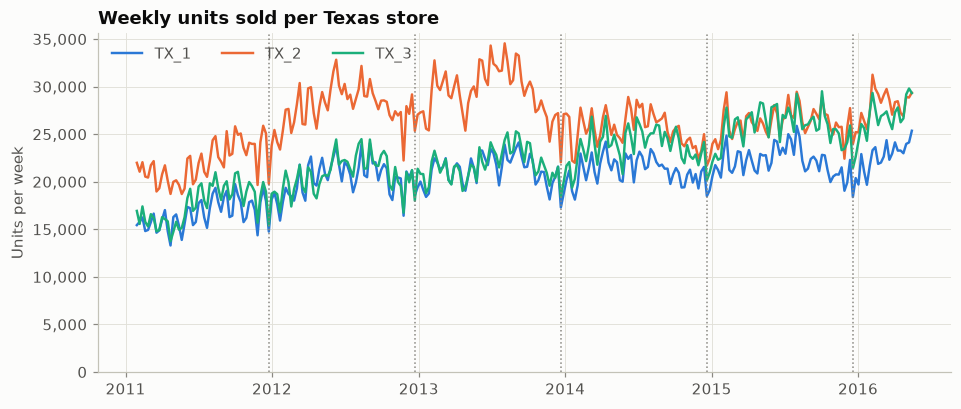

In [3]:
weekly_store = df.pivot_table(index="week_start", columns="store_id", values="sales",
                              aggfunc="sum", observed=True)

fig, ax = plt.subplots()
for store in STORES:
    ax.plot(weekly_store.index, weekly_store[store], color=STORE_COLORS[store], label=store)
for week in df.loc[df["is_christmas_week"], "week_start"].unique():
    ax.axvline(week, color=MUTED, linestyle=":", linewidth=1)
ax.set_title("Weekly units sold per Texas store")
ax.set_ylabel("Units per week")
ax.set_ylim(bottom=0)
thousands(ax)
ax.legend(loc="upper left", ncols=3)
plt.show()

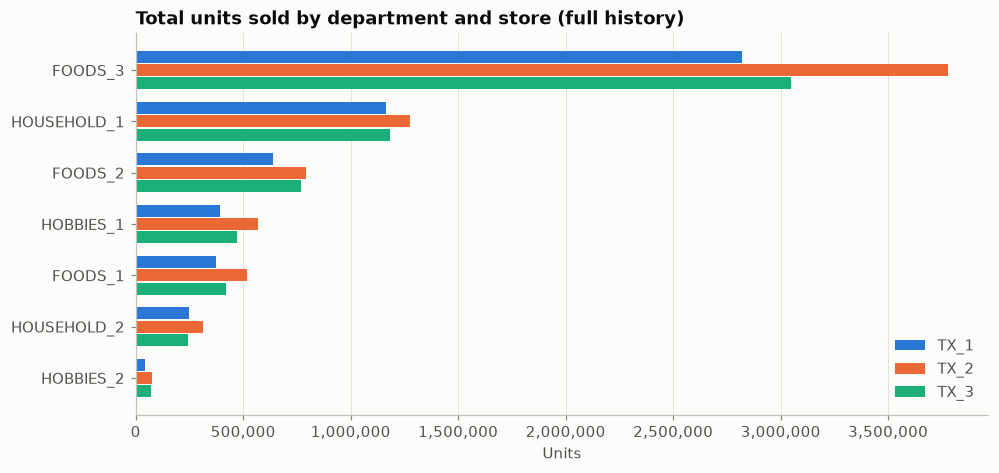

Share of all units by department:
dept_id
FOODS_3        50.2%
HOUSEHOLD_1    18.9%
FOODS_2        11.5%
HOBBIES_1       7.5%
FOODS_1         6.8%
HOUSEHOLD_2     4.2%
HOBBIES_2       1.0%

Total units by store:
store_id
TX_1    5,684,032
TX_2    7,319,623
TX_3    6,196,254


In [4]:
by_dept = df.pivot_table(index="dept_id", columns="store_id", values="sales",
                         aggfunc="sum", observed=True)
by_dept = by_dept.loc[by_dept.sum(axis=1).sort_values().index]  # largest at the top

fig, ax = plt.subplots(figsize=(10, 4.5))
bar_h = 0.26
for i, store in enumerate(STORES):
    # (1 - i) puts TX_1 on top within each group, matching the legend order
    ax.barh([y + (1 - i) * bar_h for y in range(len(by_dept))], by_dept[store],
            height=bar_h * 0.9, color=STORE_COLORS[store], label=store)
ax.set_yticks(range(len(by_dept)), by_dept.index)
ax.set_title("Total units sold by department and store (full history)")
ax.set_xlabel("Units")
ax.grid(axis="y", visible=False)
thousands(ax, axis="x")
ax.legend(loc="lower right")
plt.show()

share = (by_dept.sum(axis=1) / by_dept.values.sum()).sort_values(ascending=False)
print("Share of all units by department:")
print(share.map("{:.1%}".format).to_string())
print("\nTotal units by store:")
print(df.groupby("store_id", observed=True)["sales"].sum().map("{:,}".format).to_string())

**Reading it:** the three stores share their week-to-week swings, which suggests common drivers (calendar, SNAP, seasons) that one global model can learn across stores. Their longer-term trends differ, though: TX_2 is the largest store over the full history but falls back after 2013, while TX_3 keeps growing. Store as a categorical feature, plus recent lags, should let the model pick up each store's own level. Food, and one food department in particular, dominates volume, so volume-weighted metrics like WAPE will mostly reflect how well we forecast food.

## 3. Listings over time

The pipeline drops each item-store's weeks before its first price ("not yet listed"). The number of listed item-stores therefore grows over time. Total sales can rise simply because more items are on the shelf, so the second chart shows the average units per *listed* item-store.

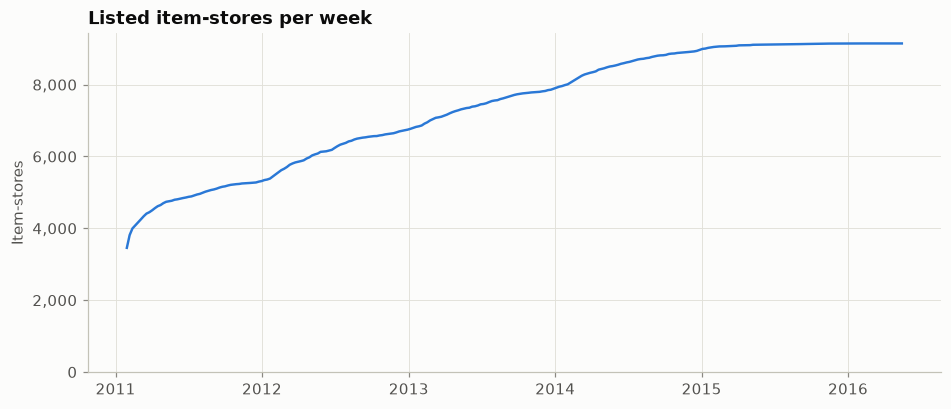

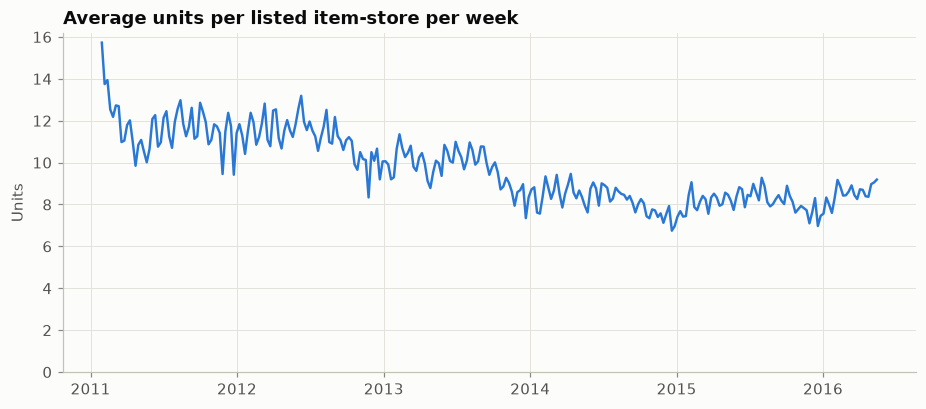

Listed item-stores in the first week: 3,457
Listed item-stores in the last week:  9,147
Average units per listed item-store, by year:
week_start
2011    11.70
2012    11.20
2013     9.79
2014     8.24
2015     8.13
2016     8.52


In [5]:
per_week = df.groupby("week_start").agg(listed=("sales", "size"), units=("sales", "sum"))
per_week["units_per_series"] = per_week["units"] / per_week["listed"]

fig, ax = plt.subplots()
ax.plot(per_week.index, per_week["listed"], color=SINGLE_COLOR)
ax.set_title("Listed item-stores per week")
ax.set_ylabel("Item-stores")
ax.set_ylim(bottom=0)
thousands(ax)
plt.show()

fig, ax = plt.subplots()
ax.plot(per_week.index, per_week["units_per_series"], color=SINGLE_COLOR)
ax.set_title("Average units per listed item-store per week")
ax.set_ylabel("Units")
ax.set_ylim(bottom=0)
plt.show()

print(f"Listed item-stores in the first week: {per_week['listed'].iloc[0]:,}")
print(f"Listed item-stores in the last week:  {per_week['listed'].iloc[-1]:,}")
print("Average units per listed item-store, by year:")
print(per_week.groupby(per_week.index.year)["units_per_series"].mean().round(2).to_string())

**Reading it:** listings grow a lot over the five years, while average units per listed item-store falls. Newly listed items tend to sell less than established ones. This is why "not yet listed" must not be treated as zero demand: those zeros would drag the early averages down for the wrong reason. It also means the series have different lengths, which matters for long lags such as "same week last year" (missing for young series). Listings are nearly flat in the final year and a half, so the backtest window at the end of the data contains few brand-new items.

## 4. Zero-sales weeks (intermittent demand)

For each item-store: the share of its listed weeks with zero sales. Even at weekly grain many series are intermittent. Again: a zero can also be a stockout.

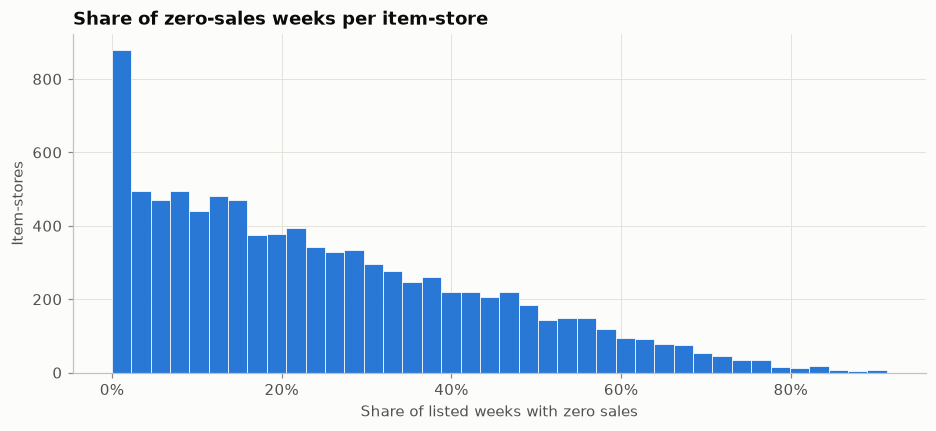

All item-store-weeks with zero sales: 24.9%
Per item-store, share of zero weeks (quantiles):
0.10     2%
0.25     9%
0.50    21%
0.75    38%
0.90    54%


In [6]:
is_zero = df["sales"].eq(0)
zero_share = is_zero.groupby([df["item_id"], df["store_id"]], observed=True).mean()

fig, ax = plt.subplots()
ax.hist(zero_share, bins=40, color=SINGLE_COLOR, edgecolor="white", linewidth=0.5)
ax.set_title("Share of zero-sales weeks per item-store")
ax.set_xlabel("Share of listed weeks with zero sales")
ax.set_ylabel("Item-stores")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

print(f"All item-store-weeks with zero sales: {is_zero.mean():.1%}")
print("Per item-store, share of zero weeks (quantiles):")
print(zero_share.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).map("{:.0%}".format).to_string())

In [7]:
zero_by_dept = (is_zero.groupby([df["dept_id"], df["store_id"]], observed=True).mean()
                .unstack().loc[lambda t: t.mean(axis=1).sort_values(ascending=False).index])
zero_by_dept.style.format("{:.0%}").set_caption("Share of zero-sales weeks by department and store")

store_id,TX_1,TX_2,TX_3
dept_id,,,
HOBBIES_2,51%,38%,42%
HOUSEHOLD_2,38%,31%,38%
HOBBIES_1,30%,22%,26%
FOODS_1,25%,22%,27%
FOODS_2,23%,23%,27%
FOODS_3,20%,18%,20%
HOUSEHOLD_1,17%,15%,17%


**Reading it:** the spread is wide. Some series sell every week and others are zero more often than not. Intermittency differs by department (see the table) rather than simply by category: HOBBIES_2 and HOUSEHOLD_2 have the most zero weeks, while HOUSEHOLD_1 and FOODS_3 have the fewest. This is why results will be split by demand type (Syntetos–Boylan: smooth, erratic, intermittent, lumpy) during evaluation, and why Poisson/Tweedie losses (which handle many zeros and non-negative counts) are a natural fit.

## 5. Seasonality

Average units per listed item-store by week of the year, pooled over all years. Using the per-series average keeps listing growth from looking like seasonality.

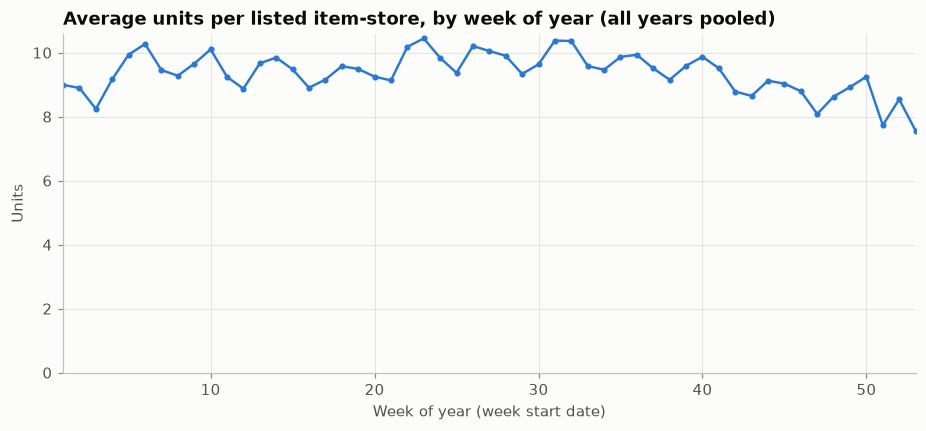

Average units per item-store-week by month of week start:
week_start
1      8.75
2      9.72
3      9.55
4      9.37
5      9.30
6     10.10
7      9.81
8      9.79
9      9.62
10     9.24
11     8.63
12     8.78
Highest / lowest month ratio: 1.17


In [8]:
woy = df["week_start"].dt.isocalendar().week.astype(int).rename("week_of_year")
season = df.groupby(woy)["sales"].mean()

fig, ax = plt.subplots()
ax.plot(season.index, season.values, color=SINGLE_COLOR, marker="o", markersize=3)
ax.set_title("Average units per listed item-store, by week of year (all years pooled)")
ax.set_xlabel("Week of year (week start date)")
ax.set_ylabel("Units")
ax.set_ylim(bottom=0)
ax.set_xlim(1, 53)
plt.show()

month = df.groupby(df["week_start"].dt.month)["sales"].mean()
print("Average units per item-store-week by month of week start:")
print(month.round(2).to_string())
print(f"Highest / lowest month ratio: {month.max() / month.min():.2f}")

**Reading it:** at the total level the yearly pattern is mild compared with the listing effect and the item-to-item differences. The sharpest single dip is around Christmas (next section). Week of year and month are still worth including as features, and seasonal naive (same week last year) is a fair baseline to beat.

## 6. Store closures: Christmas week

Stores are closed on Dec 25, so the week containing it has 6 selling days instead of 7 (`days_open = 6`). If the closure were the only effect, the week would sell about 6/7 of a normal week. The table compares each Christmas week with the average of the week before and the week after (all three stores combined).

In [9]:
weekly_total = df.groupby("wm_yr_wk")["sales"].sum()
weeks = weekly_total.index.to_list()
xmas_weeks = sorted(df.loc[df["is_christmas_week"], "wm_yr_wk"].unique())

rows = []
for wk in xmas_weeks:
    i = weeks.index(wk)
    neighbours = (weekly_total[weeks[i - 1]] + weekly_total[weeks[i + 1]]) / 2
    rows.append({
        "wm_yr_wk": wk,
        "week_start": df.loc[df["wm_yr_wk"] == wk, "week_start"].iloc[0].date(),
        "christmas_week_units": weekly_total[wk],
        "neighbour_avg_units": round(neighbours),
        "ratio_to_neighbours": weekly_total[wk] / neighbours,
    })
xmas = pd.DataFrame(rows)
print(f"Ratio expected from one closed day alone: {6 / 7:.2f}")
xmas.style.format({"christmas_week_units": "{:,}", "neighbour_avg_units": "{:,}",
                   "ratio_to_neighbours": "{:.2f}"}).hide(axis="index")

Ratio expected from one closed day alone: 0.86


wm_yr_wk,week_start,christmas_week_units,neighbour_avg_units,ratio_to_neighbours
11148,2011-12-24,"49,927","61,308",0.81
11248,2012-12-22,"61,919","69,720",0.89
11348,2013-12-21,"57,745","68,105",0.85
11447,2014-12-20,"60,326","66,606",0.91
11547,2015-12-19,"63,760","72,096",0.88


**Reading it:** the Christmas-week dip is roughly what one closed day explains. Some years fall a bit below the 6/7 line and others a bit above, so there is no consistent extra effect beyond the closure. Models still get both `days_open` and `is_christmas_week`, because the surrounding holiday weeks are unusual too and the model can learn whatever remains. The backtest window at the end of the data (spring 2016) contains no Christmas week, so this matters mostly for lag features and the seasonal naive baseline, which looks back 52 weeks.

## 7. Series that recently went silent

Item-stores that sold in the past but have zero sales in each of the last 8 weeks. In real life this could be a delisting, a long stockout, or "phantom inventory" (the system thinks there is stock, the shelf is empty). These are the cases the exception flags will look for.

In [10]:
last_weeks = sorted(df["wm_yr_wk"].unique())[-8:]
recent = df[df["wm_yr_wk"].isin(last_weeks)].groupby(["item_id", "store_id"], observed=True)["sales"].sum()
earlier = df[~df["wm_yr_wk"].isin(last_weeks)].groupby(["item_id", "store_id"], observed=True)["sales"].sum()
silent = recent[(recent == 0) & (earlier.reindex(recent.index) > 0)]

print(f"Item-stores with zero sales in each of the last 8 weeks (after earlier sales): {len(silent):,} "
      f"of {len(recent):,} ({len(silent) / len(recent):.1%})")
silent_by = (silent.reset_index()
             .merge(df[["item_id", "dept_id"]].drop_duplicates(), on="item_id")
             .pivot_table(index="dept_id", columns="store_id", values="sales",
                          aggfunc="size", fill_value=0, observed=True))
silent_by

Item-stores with zero sales in each of the last 8 weeks (after earlier sales): 144 of 9,147 (1.6%)


store_id,TX_1,TX_2,TX_3
dept_id,,,
FOODS_1,3,3,4
FOODS_2,3,5,6
FOODS_3,15,14,13
HOBBIES_1,5,1,10
HOBBIES_2,12,3,3
HOUSEHOLD_1,6,6,8
HOUSEHOLD_2,10,5,9


**Reading it:** a small share of series has gone completely quiet. Forecasting their history as if nothing changed would over-forecast them. These weeks are kept in the data, because we cannot tell a delisting from a stockout, but they are worth flagging rather than silently trusting.

## 8. What this means for modeling

- **Weekly grain helps, but intermittency remains.** Results must be split by demand type, and count-friendly losses (Poisson/Tweedie) suit the data.
- **Food drives volume**, so aggregate WAPE mostly reflects food. Department-level results show the rest.
- **Listing growth is real.** "Not yet listed" weeks are excluded, series have different lengths, and long lags (52 weeks) will be missing for young series.
- **Calendar effects:** Christmas week loses about one day's sales and is flagged; SNAP days, events, week of year and month are known in advance and can be used for the target week.
- **Sales ≠ demand.** Zero runs may be stockouts. The exception flags surface them instead of hiding them.